# Colab: train & evaluate CLIPSeg for Drywall QA
**Before running:** Runtime → Change runtime type → **T4 GPU**. Then Runtime → Run all.

Runs are written to Google Drive, so checkpoints survive a disconnect.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Get the code + data
For a private repo use `https://<TOKEN>@github.com/...` (GitHub → Settings → Developer settings → fine-grained token, read-only).

In [2]:
REPO = "https://github.com/VVISHUS/ORIGIN_Prompted_Segmentation.git"
!git clone -q --depth 1 $REPO /content/repo
%cd /content/repo
!pip install -q -r requirements.txt

/content/repo


## 2. Persist runs on Google Drive

In [3]:
from google.colab import drive
drive.mount("/content/drive")
RUNS = "/content/drive/MyDrive/drywall_runs"
CFG = "configs/clipseg_ft.yaml"
import os; os.makedirs(RUNS, exist_ok=True)

Mounted at /content/drive


## 3. Prepare masks + augmentation-aware split (≈1–2 min)

In [4]:
!python prepare_data.py --config $CFG

crack/test: 100% 4/4 [00:00<00:00, 38.62it/s]
crack/train: 100% 5164/5164 [00:45<00:00, 114.48it/s]
crack/valid: 100% 201/201 [00:01<00:00, 127.11it/s]
taping/train: 100% 820/820 [00:06<00:00, 134.72it/s]
taping/valid: 100% 202/202 [00:01<00:00, 130.72it/s]

dropped degenerate boxes: 19

images per split (augmentation-aware, seed 42):
split    train  val  test  total  sources
dataset                                  
crack     3759  805   805   5369     1110
taping     718  147   157   1022      164


## 4. Zero-shot baseline (no training)

In [5]:
!python evaluate.py --config $CFG --set output_dir={RUNS}

config.json: 100% 4.73k/4.73k [00:00<00:00, 14.1MB/s]

model.safetensors: downloading bytes:  22% 136M/603M [00:01<00:02, 193MB/s, 9.35MB/s  ] 
model.safetensors: downloading bytes:  32% 195M/603M [00:01<00:01, 233MB/s, 15.5MB/s  ]
model.safetensors: downloading bytes:  44% 266M/603M [00:01<00:01, 199MB/s, 23.2MB/s  ]
model.safetensors: downloading bytes:  49% 293M/603M [00:01<00:01, 178MB/s, 25.4MB/s  ]
model.safetensors: downloading bytes:  65% 389M/603M [00:02<00:00, 221MB/s, 32.1MB/s  ]
model.safetensors: downloading bytes:  71% 429M/603M [00:02<00:00, 212MB/s, 36.5MB/s  ]
model.safetensors: reconstructing file:  89% 536M/603M [00:02<00:00, 238MB/s, 36.0MB/s  ]
model.safetensors: downloading bytes: 100% 432M/432M [00:02<00:00, 145MB/s, 37.7MB/s  ]
model.safetensors: reconstructing file: 100% 603M/603M [00:02<00:00, 202MB/s, 52.7MB/s  ]
Loading weights: 100% 462/462 [00:00<00:00, 4837.71it/s]
preprocessor_config.json: 100% 380/380 [00:00<00:00, 1.96MB/s]
tokenizer_config.json: 100% 

## 5. Fine-tune
Override anything with `--set`, e.g. `train.epochs=30 optim.lr=5e-4`.

In [9]:
!python train.py --config $CFG --set train.epochs=40  output_dir={RUNS}

Loading weights: 100% 462/462 [00:00<00:00, 5036.13it/s]
run: /content/drive/MyDrive/drywall_runs/clipseg_ft-20261016-221939
device: cuda | amp: True | params: 150.7M total, 1.13M trainable | train batches/epoch: 279 | val pairs: 1904
epoch   0 (pretrained) | val mIoU 0.194 (crack 0.283 / taping 0.104)
epoch   1 | loss 0.9013 | val mIoU 0.458 (crack 0.372 / taping 0.543)  ← best | 149s
epoch   2 | loss 0.5517 | val mIoU 0.504 (crack 0.404 / taping 0.603)  ← best | 149s
epoch   3 | loss 0.4959 | val mIoU 0.523 (crack 0.420 / taping 0.625)  ← best | 147s
epoch   4 | loss 0.4567 | val mIoU 0.521 (crack 0.407 / taping 0.635) | 147s
epoch   5 | loss 0.4354 | val mIoU 0.524 (crack 0.411 / taping 0.636)  ← best | 147s
epoch   6 | loss 0.4236 | val mIoU 0.540 (crack 0.431 / taping 0.649)  ← best | 148s
epoch   7 | loss 0.4109 | val mIoU 0.548 (crack 0.441 / taping 0.655)  ← best | 149s
epoch   8 | loss 0.3996 | val mIoU 0.555 (crack 0.445 / taping 0.665)  ← best | 148s
epoch   9 | loss 0.3842 

In [12]:
RUN = f"{RUNS}/clipseg_ft-20261016-221939"
!cat "{RUN}/train_info.json"
!python evaluate.py --run "{RUN}"
!python analyze_errors.py --eval-dir "{RUN}/eval_test"
!python predict.py --run "{RUN}" --split test


{
  "train_time_s": 4224.9637677669525,
  "epochs_run": 28,
  "best_epoch": 23,
  "best_val_mIoU": 0.5933070403913102,
  "params_total": 150747746,
  "params_trainable": 1127009,
  "model_size_mb_fp32": 575.0591049194336,
  "checkpoint_mb": 4.315201759338379,
  "device": "cuda",
  "gpu": "Tesla T4"
Loading weights: 100% 462/462 [00:00<00:00, 5629.33it/s]
thresholds: {'crack': 0.4, 'taping': 0.45}
## Results on `test`

| prompt | n | IoU | IoU std | IoU p10 | Dice | Dice std | threshold | leak (other prompt fg) |
|---|---|---|---|---|---|---|---|---|
| segment crack | 805 | 0.492 | 0.180 | 0.252 | 0.638 | 0.180 | 0.400 | 0.000 |
| segment taping area | 157 | 0.732 | 0.122 | 0.588 | 0.838 | 0.094 | 0.450 | 0.001 |

**mIoU 0.612 | mDice 0.738**

### IoU by scene bucket (consistency)

| class | factor | low | mid | high | spread (max-min) |
|---|---|---|---|---|---|
| crack | brightness | 0.484 | 0.503 | 0.491 | 0.020 |
| crack | contrast | 0.499 | 0.496 | 0.482 | 0.017 |
| crack | sharpne

## 6. Evaluate on test + write prediction masks

In [13]:
import glob
RUN = sorted(glob.glob(f"{RUNS}/clipseg_ft-2*"))[-1]   # latest timestamped run
# or pin it: RUN = f"{RUNS}/clipseg_ft-20261016-164600"
print("evaluating:", RUN)
!python evaluate.py --run "{RUN}"
!python predict.py --run "{RUN}" --split test

evaluating: /content/drive/MyDrive/drywall_runs/clipseg_ft-20261016-221939
Loading weights: 100% 462/462 [00:00<00:00, 4271.45it/s]
thresholds: {'crack': 0.4, 'taping': 0.45}
## Results on `test`

| prompt | n | IoU | IoU std | IoU p10 | Dice | Dice std | threshold | leak (other prompt fg) |
|---|---|---|---|---|---|---|---|---|
| segment crack | 805 | 0.492 | 0.180 | 0.252 | 0.638 | 0.180 | 0.400 | 0.000 |
| segment taping area | 157 | 0.732 | 0.122 | 0.588 | 0.838 | 0.094 | 0.450 | 0.001 |

**mIoU 0.612 | mDice 0.738**

### IoU by scene bucket (consistency)

| class | factor | low | mid | high | spread (max-min) |
|---|---|---|---|---|---|
| crack | brightness | 0.484 | 0.503 | 0.491 | 0.020 |
| crack | contrast | 0.499 | 0.496 | 0.482 | 0.017 |
| crack | sharpness | 0.474 | 0.472 | 0.526 | 0.053 |
| taping | brightness | 0.737 | 0.767 | 0.688 | 0.079 |
| taping | contrast | 0.717 | 0.773 | 0.707 | 0.066 |
| taping | sharpness | 0.732 | 0.724 | 0.739 | 0.015 |

### Runtime & footprin

In [15]:
!python analyze_errors.py --eval-dir "{RUN}/eval_test"


GT stats: 100% 962/962 [00:06<00:00, 142.67it/s]
# Error analysis

## Overall (oracle_iou / oracle_grid = ceilings at 352 px / 22×22 grid; pred_vs_gt > 1 = over-segmenting)

| prompt_class | n | iou | oracle_iou | oracle_grid | pred_vs_gt | width_px |
|---|---|---|---|---|---|---|
| crack | 805 | 0.492 | 0.997 | 0.438 | 1.105 | 18.300 |
| taping | 157 | 0.732 | 1.000 | 0.923 | 1.026 | 89.488 |

## Error type share (rows sum to 1)

| prompt_class | miss | over | shape | under |
|---|---|---|---|---|
| crack | 0.015 | 0.302 | 0.470 | 0.214 |
| taping | 0.000 | 0.045 | 0.930 | 0.025 |

## Mean IoU per error type

| prompt_class | miss | over | shape | under |
|---|---|---|---|---|
| crack | 0.011 | 0.364 | 0.608 | 0.451 |
| taping | nan | 0.446 | 0.753 | 0.451 |

## IoU by GT stroke width (px at 640)

| prompt_class | width_px | n | iou | oracle_iou | oracle_grid | pred_vs_gt |
|---|---|---|---|---|---|---|
| crack | <5 | 68 | 0.227 | 0.982 | 0.000 | 3.542 |
| crack | 5-10 | 150 | 0.441 |

In [17]:
import glob, cv2
for cls in ["segment_crack", "segment_taping_area"]:
    files = glob.glob(f"{RUN}/predictions_test/*__{cls}.png")
    empty = [f for f in files if cv2.imread(f, 0).max() == 0]
    print(f"{cls}: {len(empty)} empty of {len(files)}")


segment_crack: 7 empty of 805
segment_taping_area: 0 empty of 157


## 7. Look at the results

results of: /content/drive/MyDrive/drywall_runs/clipseg_ft-20261016-221939


## Results on `test`

| prompt | n | IoU | IoU std | IoU p10 | Dice | Dice std | threshold | leak (other prompt fg) |
|---|---|---|---|---|---|---|---|---|
| segment crack | 805 | 0.492 | 0.180 | 0.252 | 0.638 | 0.180 | 0.400 | 0.000 |
| segment taping area | 157 | 0.732 | 0.122 | 0.588 | 0.838 | 0.094 | 0.450 | 0.001 |

**mIoU 0.612 | mDice 0.738**

### IoU by scene bucket (consistency)

| class | factor | low | mid | high | spread (max-min) |
|---|---|---|---|---|---|
| crack | brightness | 0.484 | 0.503 | 0.491 | 0.020 |
| crack | contrast | 0.499 | 0.496 | 0.482 | 0.017 |
| crack | sharpness | 0.474 | 0.472 | 0.526 | 0.053 |
| taping | brightness | 0.737 | 0.767 | 0.688 | 0.079 |
| taping | contrast | 0.717 | 0.773 | 0.707 | 0.066 |
| taping | sharpness | 0.732 | 0.724 | 0.739 | 0.015 |

### Runtime & footprint

| device | ms_per_image | ms_per_image_std | params_total | params_finetuned | model_size_mb_fp32 | checkpoint_mb |
|---|---|---|---|---|---|---|
| cuda | 23.280 | 3.929 | 150747746 | 1127009 | 575.059 | 4.315 |


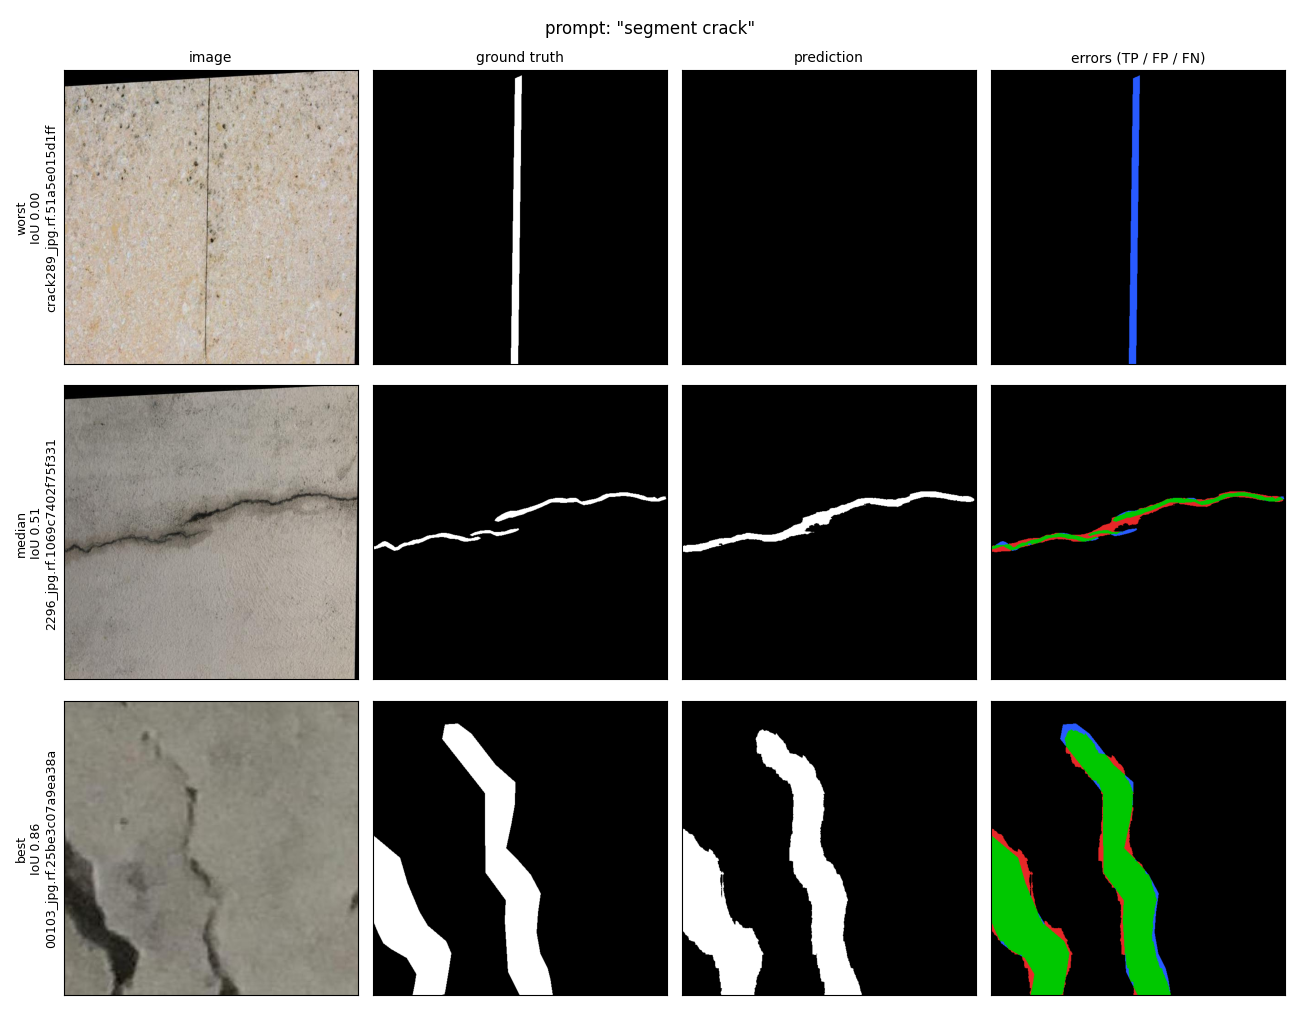

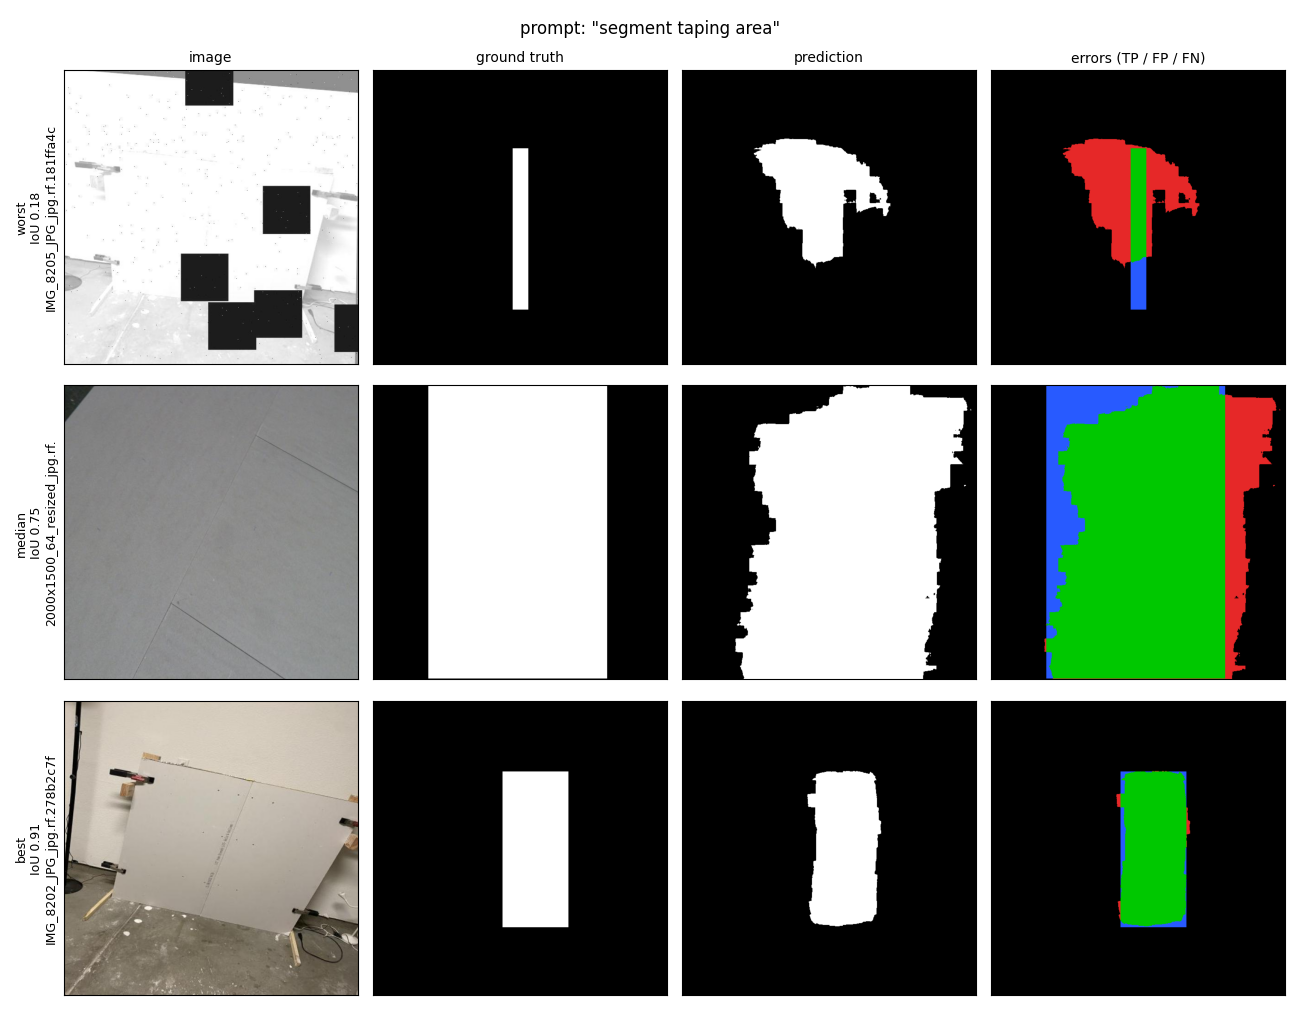

In [14]:
from IPython.display import Markdown, Image, display
print("results of:", RUN)
display(Markdown(open(f"{RUN}/eval_test/results.md").read()))
for f in sorted(glob.glob(f"{RUN}/eval_test/examples_*.png")):
    display(Image(f))